# Pretraining and the data scaling law (CNN, MNIST)
Target task: digits **3, 5, 8** (3-way; confusable digits, so the error stays above
test-set resolution). Generalization (test error and test cross-entropy) as a function of
target training set size $m$, trained from scratch vs. fine-tuned from a CNN pretrained on
other digits. Levels of pretraining (all images of each source set):
- **2 digits**: 2, 7 (~12k images)
- **4 digits**: 0, 2, 4, 7 (~24k)
- **all digits**: the 7 non-target digits 0, 1, 2, 4, 6, 7, 9 (~42k) + a small fixed subset of
  the target digits (300 images per class; artificial upper level). These held-out target images
  are removed from the target training pool for *every* condition.

**Part 1** runs the simulation (code in `network_utils.py`) and saves every trained network to
`sim_dir` (`data/simulation/mnist_pretrain/`, see its README for the file format).
**Parts 2 and 3** evaluate the saved networks (end of training / early-stopped) and analyse
their learning curves (analysis code in `utils.py`); they need only the setup cells below.

In [1]:
# imports (torch is imported by the parts that need it)
import numpy as np
import matplotlib.pyplot as plt

from utils import RepeatedCurve, fit_curves, print_fits, plot_curve_fits, plot_phi_alpha

In [2]:
# figure formating
import seaborn as sns
custom_params = {"axes.spines.right": False,
                 "axes.spines.top": False}
sns.set_theme(style="ticks", rc=custom_params)

import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
mpl.rcParams['figure.dpi'] = 100   # display
mpl.rcParams['savefig.dpi'] = 300  # saved figures

In [3]:
# settings shared by simulation and analysis
sim_dir = './data/simulation/mnist_pretrain'  # pretrained and final trained networks (released)
target_digits = [3, 5, 8]
n_mix = 300  # target images per class held out for the 'all digits' pretraining set
n_repeat = 8

# conditions in order of increasing pretraining, and their saved networks
conditions = ['scratch', 'pretrain 2 digits', 'pretrain 4 digits', 'pretrain all digits']
net_path = lambda cond: f"{sim_dir}/networks_{cond.replace(' ', '_')}.pt"

# analysis: fit range, and colors from scratch (blue) towards the strongest prior (green)
m_range = (2 ** 5, 2 ** 13)
colors = dict(zip(conditions, ['tab:blue', 'tab:cyan', '#7fc97f', 'tab:green']))

---
## Part 1: Simulation
Simulation code (data, CNN, training, pretraining, `NetworkCurve`) is in `network_utils.py`.

Fine-tuning: pretrained conv + fc features, **new random head** (source and target
labels differ; for *all digits* the pretrained 3/5/8 outputs are also discarded), all weights trained.

Training protocol: same learner at every $m$ (AdamW + cosine decay), trained to
approximate convergence: `max(min_steps, min_epochs)` SGD steps.
Repeated over random target subsets + initializations (one pretrained network per repeat).
Results are cached: re-running a cell with an existing results / cache file loads it instead of training.

In [ ]:
import torch
from network_utils import (device, load_mnist, split_digits, hold_out_per_class, merge_sources,
                           CNN, NetworkCurve, pretrain, pretrained_init)

torch.backends.cudnn.benchmark = True
print(device)

### Data

In [ ]:
mnist = load_mnist()

source_digits = {'7 digits': [0, 1, 2, 4, 6, 7, 9],
                 '4 digits': [0, 2, 4, 7],
                 '2 digits': [2, 7]}

# fixed held-out subset of the target training set (n_mix per class) for the 'all digits'
# level; removed from the target training pool of every condition
target, target_mix = hold_out_per_class(split_digits(mnist, target_digits), n_mix)

sources = {k: split_digits(mnist, d) for k, d in source_digits.items()}

print('target', target_digits, 'train pool', len(target[0]), 'held out', len(target_mix[0]),
      'test', len(target[2]))
for k, d in sources.items():
    print('source', k, source_digits[k], 'train', len(d[0]), 'test', len(d[2]))

target [3, 5, 8] train pool 16503 held out 900 test 2876
source 7 digits [0, 1, 2, 4, 6, 7, 9] train 42597 test 7124
source 4 digits [0, 2, 4, 7] train 23988 test 4022
source 2 digits [2, 7] train 12223 test 2060


### Pretraining

In [ ]:
n7 = len(source_digits['7 digits'])
all_digits = merge_sources(sources['7 digits'], target_mix, n7)
levels = {  # name: (pretraining data, n_classes)
    '2 digits': (sources['2 digits'], len(source_digits['2 digits'])),
    '4 digits': (sources['4 digits'], len(source_digits['4 digits'])),
    'all digits': (all_digits, n7 + len(target_digits)),
}

pretrained = {}
for k, (d, n_classes) in levels.items():
    print(f'--- source {k} ({len(d[0])} images, {n_classes} classes)')
    pretrained[k] = pretrain(d, n_classes=n_classes, n_repeat=n_repeat,
                             cache=f"{sim_dir}/pretrain_{k.replace(' ', '_')}.pt")

--- source 2 digits (12223 images, 2 classes)
loaded ./data/simulation/mnist_pretrain/pretrain_2_digits.pt
--- source 4 digits (23988 images, 4 classes)
loaded ./data/simulation/mnist_pretrain/pretrain_4_digits.pt
--- source all digits (43497 images, 10 classes)
loaded ./data/simulation/mnist_pretrain/pretrain_all_digits.pt


### Target networks
For every condition, $m$ and repeat: a network trained on the target subset from scratch or from the
pretrained features (`NetworkCurve.run`). Saved per condition: the initial weights, the
early-stopped weights (first zero training error, see Part 3) and the final weights.

In [ ]:
train_size = 2 ** np.arange(4, 15)
cnn_target = lambda: CNN(n_classes=len(target_digits))

inits = {'scratch': None}
inits.update({f'pretrain {k}': pretrained_init(s) for k, s in pretrained.items()})
assert list(inits) == conditions

for cond, init in inits.items():
    print(f'--- {cond}')
    NetworkCurve(target, cnn_target, init=init, train_size=train_size,
                 n_repeat=n_repeat).run(net_path(cond))

--- scratch
loaded ./data/simulation/mnist_pretrain/networks_scratch.pt
--- pretrain 2 digits
loaded ./data/simulation/mnist_pretrain/networks_pretrain_2_digits.pt
--- pretrain 4 digits
loaded ./data/simulation/mnist_pretrain/networks_pretrain_4_digits.pt
--- pretrain all digits
loaded ./data/simulation/mnist_pretrain/networks_pretrain_all_digits.pt


---
## Part 2: Learning curves at the end of training
Evaluates the saved networks (final weights) on the target test set; only the setup cells above
are needed (torch, CPU or GPU).

In [ ]:
from network_utils import load_mnist, split_digits, hold_out_per_class, load_networks, evaluate_networks

# target data: test set, and the pool the training subsets were drawn from
target, _ = hold_out_per_class(split_digits(load_mnist(), target_digits), n_mix)
nets = {cond: load_networks(net_path(cond)) for cond in conditions}

curves = {cond: RepeatedCurve(evaluate_networks(res, 'final', target)) for cond, res in nets.items()}
for k, cc in curves.items():
    print(f'{k:28s} m = {cc.train_size.min()}..{cc.train_size.max()}  '
          f'max train error = {cc.train_errors.max():.4f}')

### Two-part learning curve, $m \in [2^5, 2^{13}]$
Test error and test cross-entropy, each fitted with the theory-derived two-part curve
(`PACBayesCurve` in `utils.py`):
$g(m) = g^* + \frac{2}{3}\frac{\phi}{m} + \left(\frac{2\phi}{m}\right)^\alpha$
on the range $2^5 \le m \le 2^{13}$ only. Least squares on **log** error (`loss='log'`, relative
residuals): the curves span ~1.5 decades, and the default linear-error fit is dominated by the
small-$m$ points and misses the tail that sets the floor.

The floor $g^*$ (per metric) is **shared by all conditions** (the irreducible error of the target task,
which pretraining should not change), chosen to minimize the summed squared error of all fits.
Given the floor, each condition's $(\phi, \alpha)$ is fitted independently.
Error bars: bootstrap over the 8 repeats (resampled with the same indices for all conditions,
whole fit redone; 1000 draws).

Effective data $m_\text{eff}/m$ from inverting the fitted scratch curve (numerically).

In [ ]:
results = fit_curves(curves, m_range)
print_fits(results)

--- error: shared floor = 0.0028
scratch                      alpha 0.754 +- 0.036   phi 1.295 +- 0.244   r2 0.9656
pretrain 2 digits            alpha 0.715 +- 0.034   phi 0.869 +- 0.201   r2 0.9937
pretrain 4 digits            alpha 0.740 +- 0.046   phi 0.789 +- 0.213   r2 0.9940
pretrain all digits          alpha 0.692 +- 0.073   phi 0.338 +- 0.196   r2 0.9911
--- cross-entropy: shared floor = 0.0104
scratch                      alpha 0.808 +- 0.056   phi 11.955 +- 1.762   r2 0.9638
pretrain 2 digits            alpha 0.741 +- 0.058   phi 7.061 +- 1.603   r2 0.9889
pretrain 4 digits            alpha 0.777 +- 0.074   phi 5.828 +- 1.433   r2 0.9951
pretrain all digits          alpha 0.724 +- 0.119   phi 2.599 +- 1.250   r2 0.9845


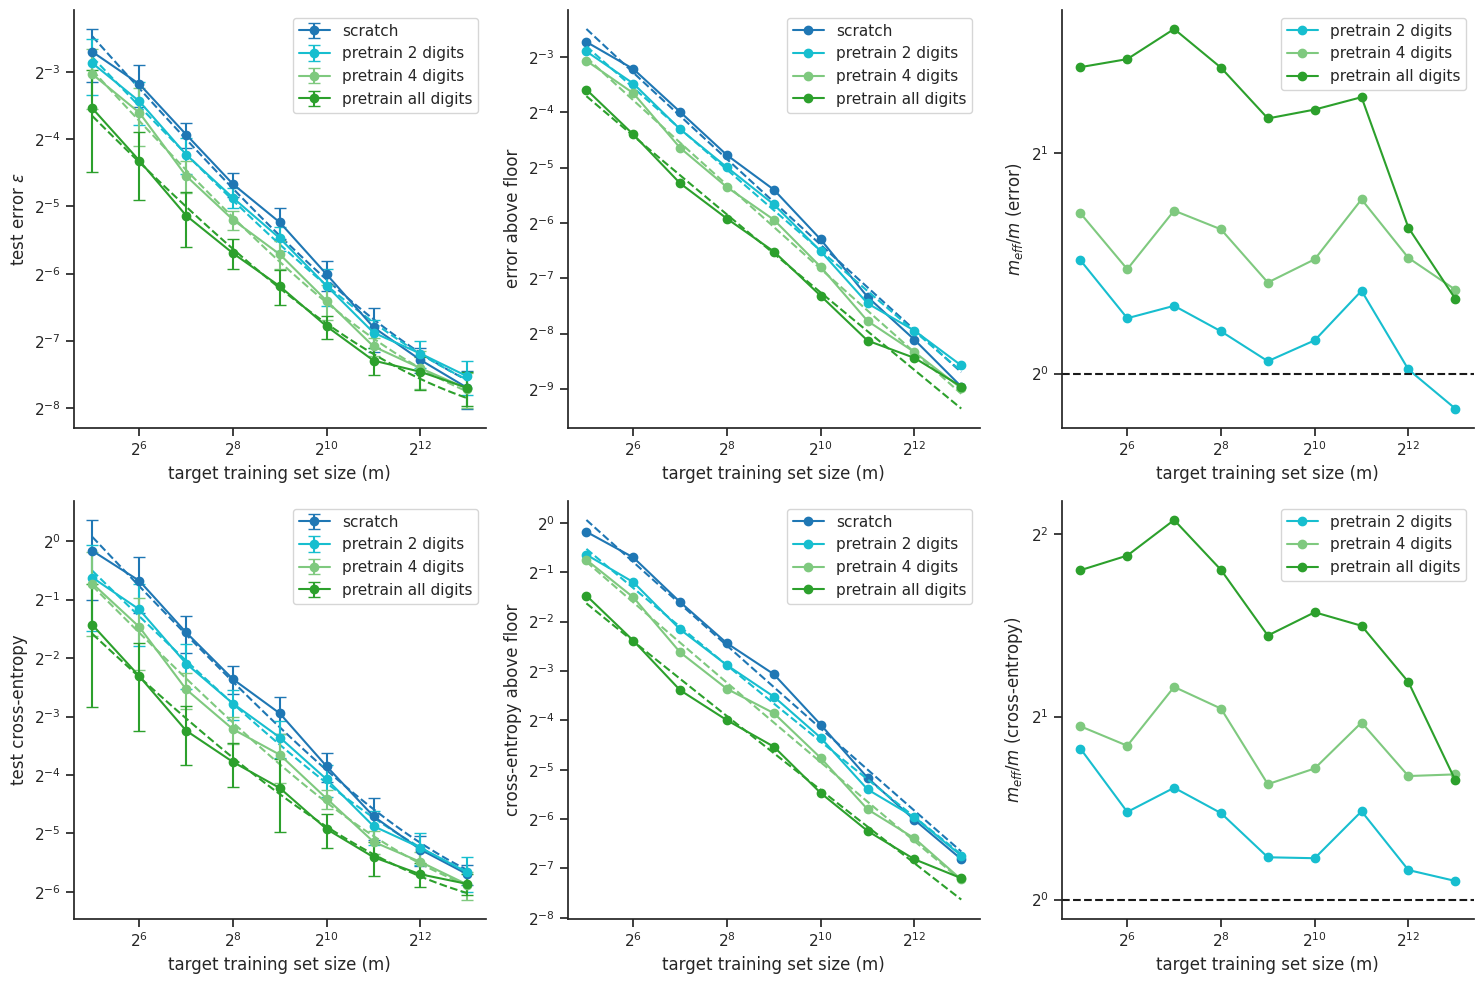

In [ ]:
# rows: test error, test cross-entropy
plot_curve_fits(curves, results, m_range, colors)

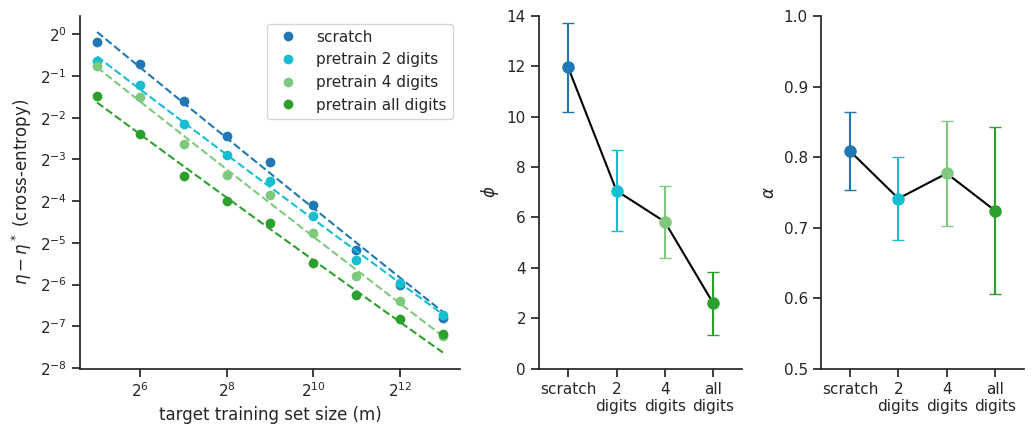

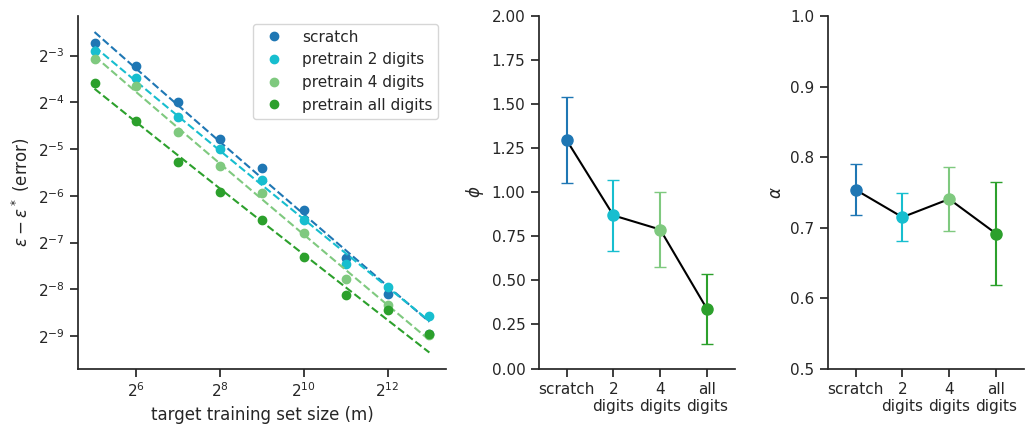

In [ ]:
plot_phi_alpha(curves, results['loss'], 'loss', r'$\eta - \eta^*$ (cross-entropy)', m_range, colors,
               (0.5, 1.0), (0, 14))

plot_phi_alpha(curves, results['error'], 'error', r'$\epsilon - \epsilon^*$ (error)', m_range, colors,
               (0.5, 1.0), (0, 2))

### Example images (paper)
One training image per digit, ordered so that each (nested) pretraining set is a contiguous block:
`1, 6, 9, 0, 4, 2, 7` (nested from the right): 2 digits = {2, 7}, 4 digits = {0, 4, 2, 7},
7 digits = all seven;
the target digits 3, 5, 8 are grouped on the right (all digits = the whole row).

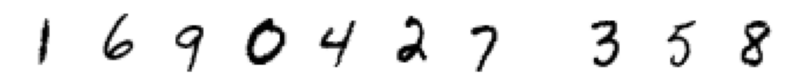

In [ ]:
from torchvision import datasets

source_order = [1, 6, 9, 0, 4, 2, 7]
target_order = [3, 5, 8]

ds = datasets.MNIST('./data/vision', train=True)
X_all, y_all = ds.data.numpy() / 255.0, ds.targets.numpy()


def prototype(d, rank=0):
    # training image of digit d closest to the class mean (a typical example);
    # rank > 0 takes the next-closest ones
    X_d = X_all[y_all == d]
    return X_d[np.argsort(((X_d - X_d.mean(axis=0)) ** 2).sum(axis=(1, 2)))[rank]]


ranks = {5: 1}  # the closest 5 has a stray speck


# source digits | gap | target digits
order = source_order + [None] + target_order
fig = plt.figure(figsize=(10, 1.3))
gs = fig.add_gridspec(1, len(order), wspace=0.15,
                      width_ratios=[0.6 if d is None else 1 for d in order])
for i, d in enumerate(order):
    if d is None:
        continue
    ax = fig.add_subplot(gs[0, i])
    ax.imshow(prototype(d, ranks.get(d, 0)), cmap='gray_r')
    ax.axis('off')

plt.savefig('./digits_row.pdf', bbox_inches='tight')
plt.show()

---
## Part 3: $\phi$ from the networks
**Early stopping.** Training runs a fixed number of steps, most of them after the training set is
already fit (training error = 0); the weights then keep moving away from $w_0$ without learning anything new. So we stop
each network at the first point its training error reaches 0 (saved by Part 1 next to the final weights).
Needs only the setup cells.

In [ ]:
from network_utils import load_mnist, split_digits, hold_out_per_class, load_networks, evaluate_networks

# target data: test set, and the pool the training subsets were drawn from
target, _ = hold_out_per_class(split_digits(load_mnist(), target_digits), n_mix)
nets = {cond: load_networks(net_path(cond)) for cond in conditions}

es_curves = {cond: RepeatedCurve(evaluate_networks(res, 'early_stop', target)) for cond, res in nets.items()}
for k, cc in es_curves.items():
    print(f"{k:28s} max train error = {cc.train_errors.max():.4f}  "
          f"early-stop step (median over repeats) {np.median(nets[k]['early_stop_step'], axis=1).astype(int)}")

scratch                      max train error = 0.0000  early-stop step (median over repeats) [  12   17   22   30   45   70  117  187  415  862 1662]
pretrain 2 digits            max train error = 0.0000  early-stop step (median over repeats) [  10   15   20   25   40   55   85  167  325  692 1490]
pretrain 4 digits            max train error = 0.0000  early-stop step (median over repeats) [  10   12   15   20   40   55   85  162  315  645 1425]
pretrain all digits          max train error = 0.0000  early-stop step (median over repeats) [  10   10   12   22   27   47   72  132  302  555 1192]


### Learning curves of the early-stopped networks
Same analysis as Part 2 (test error / cross-entropy vs. $m$, two-part fit for $\phi$ and $\alpha$).
Error bars: bootstrap over the 8 training runs per condition and $m$.

--- error: shared floor = 0.0027
scratch                      alpha 0.753 +- 0.019   phi 1.839 +- 0.189   r2 0.9713
pretrain 2 digits            alpha 0.734 +- 0.022   phi 1.367 +- 0.154   r2 0.9987
pretrain 4 digits            alpha 0.744 +- 0.020   phi 1.190 +- 0.159   r2 0.9984
pretrain all digits          alpha 0.712 +- 0.036   phi 0.656 +- 0.140   r2 0.9801
--- cross-entropy: shared floor = 0.0069
scratch                      alpha 0.715 +- 0.023   phi 6.557 +- 0.543   r2 0.9361
pretrain 2 digits            alpha 0.679 +- 0.022   phi 4.553 +- 0.395   r2 0.9984
pretrain 4 digits            alpha 0.699 +- 0.026   phi 3.936 +- 0.485   r2 0.9995
pretrain all digits          alpha 0.682 +- 0.037   phi 2.368 +- 0.426   r2 0.9836


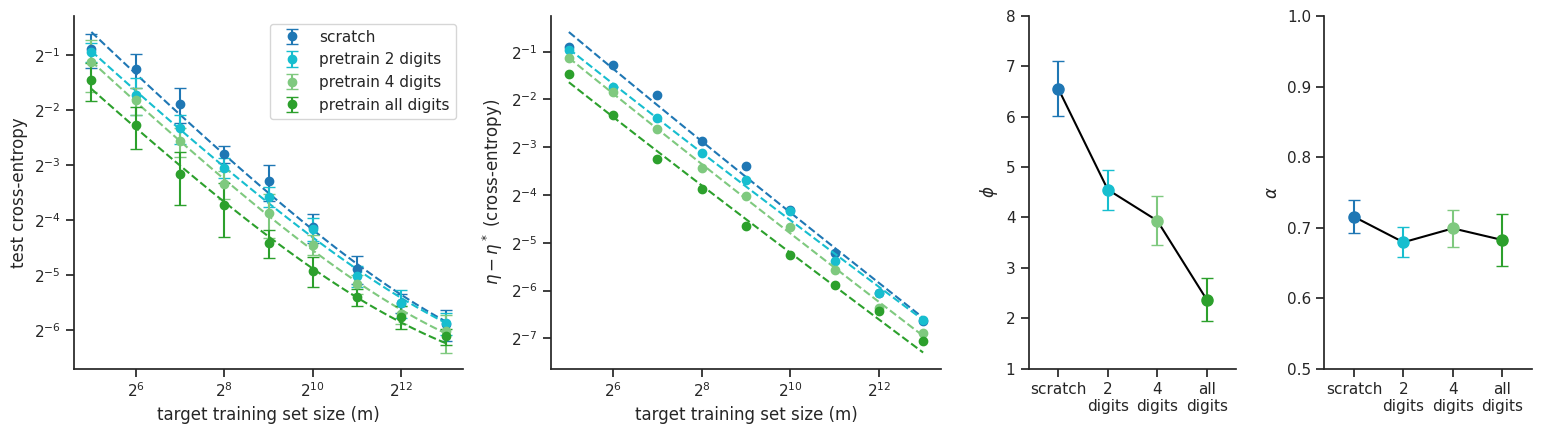

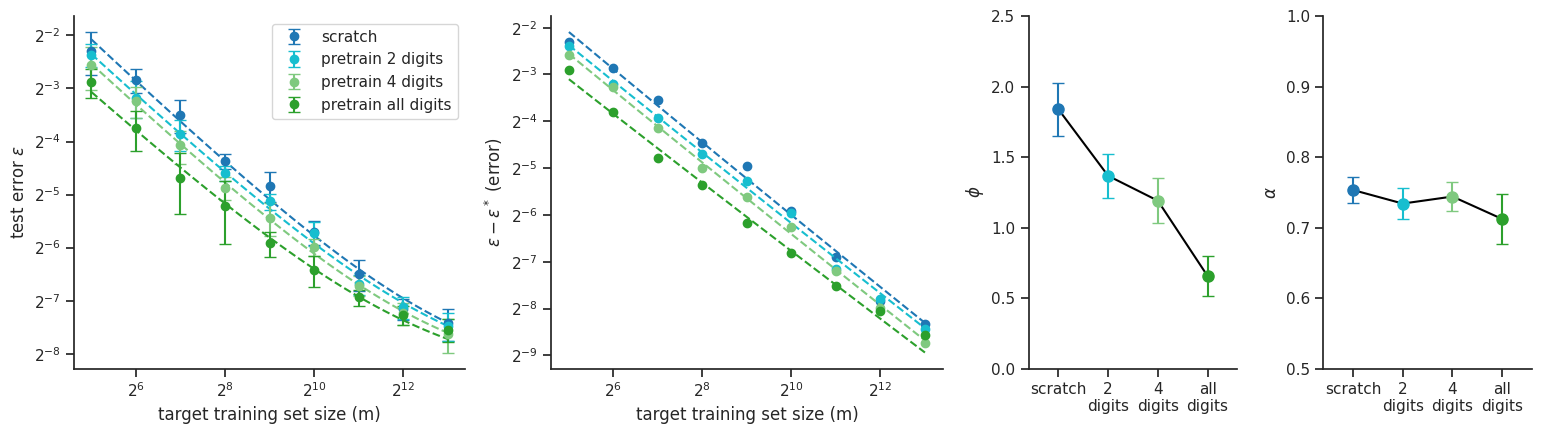

In [ ]:
es_results = fit_curves(es_curves, m_range)
print_fits(es_results)

# paper figures
plot_phi_alpha(es_curves, es_results['loss'], 'loss', r'$\eta - \eta^*$ (cross-entropy)', m_range, colors,
               (0.5, 1.0), (1, 8), path='./pretrain_cross_entropy.pdf', raw=True)

plot_phi_alpha(es_curves, es_results['error'], 'error', r'$\epsilon - \epsilon^*$ (error)', m_range, colors,
               (0.5, 1.0), (0, 2.5), path='./pretrain_error.pdf', raw=True)

### Estimate $\Phi$ from network parameters

### Estimating $\phi$ from the weights
$\phi$ plays the role of $\mathrm{KL}(Q \,\|\, P)$: the information the learner needs to move from its
prior $P$ to a posterior $Q$ that fits the training set. We build both as isotropic Gaussians over the
$k$ network weights:
the posterior $Q = \mathcal{N}(w, \sigma_Q^2 I)$ around the early-stopped weights $w$, and the prior
$P = \mathcal{N}(w_0, \sigma_P^2 I)$ around the initial weights $w_0$ (random init, or pretrained
features + random head; neither depends on the target training set). Then

$$\mathrm{KL}(Q \,\|\, P) = \frac{\|w - w_0\|^2}{2\sigma_P^2}
+ \frac{k}{2}\left[\frac{\sigma_Q^2}{\sigma_P^2} - 1 + \log\frac{\sigma_P^2}{\sigma_Q^2}\right].$$

**1. Distance from the init.** With one fixed width for everything ($\sigma_P = \sigma_Q = \sigma$), the
bracket vanishes and $\mathrm{KL} = \|w - w_0\|^2 / 2\sigma^2$: the squared distance the weights moved
(up to the arbitrary scale $\sigma$, so only ratios between networks are meaningful).

**2. Flatness-calibrated KL** (the PAC-Bayes flatness measure of Jiang et al. 2019,
*Fantastic generalization measures*):
- $\sigma_Q$ is the flatness of the trained network: the largest weight noise that keeps its training
  error within $\epsilon = 0.2$ of the noise-free error (bisection on $\sigma$, 10 noise draws per step).
- $\sigma_P$ is the prior width that minimizes the KL.   
  A narrow prior puts $w$ in its tails (first term
  large); a wide one spreads over a volume that $Q$ barely fills (log term large). 
  We choose to optimize $\sigma_P^2$ to minimize this quantity.  
  (Think of this as applying a union bound over a small grid, so we can do this at a small cost.)

  The resulted solution
  $\sigma_P^2 = \sigma_Q^2 + \|w - w_0\|^2 / k$.
  It gives

$$\widehat{\mathrm{KL}} = \frac{k}{2}\log\!\left(1 + \frac{\|w - w_0\|^2}{k\,\sigma_Q^2}\right)
\approx \frac{\|w - w_0\|^2}{2\sigma_Q^2},$$

  Interpretation: the distance moved in units of the network's own flatness: a network in a flat minimum can move
  far and still count as little information.

In [15]:
# distance from the init and flatness-calibrated KL of the early-stopped networks at m = m_kl,
# for every repeat
from network_utils import subset, cnn_from_state, param_distance, flatness_sigma, pac_bayes_kl

m_kl = 2 ** 10
eps = 0.2  # flatness tolerance: noisy training error within eps of the noise-free error

measures = {}
for cond, res in nets.items():
    k = sum(v.numel() for v in res['init'][0].values())
    i = list(res['train_size']).index(m_kl)
    d2, sigma = np.zeros(n_repeat), np.zeros(n_repeat)
    for r in range(n_repeat):
        state = res['early_stop'][i][r]
        d2[r] = param_distance(state, res['init'][r])[0]
        sigma[r] = flatness_sigma(cnn_from_state(state), *subset(*target[:2], m_kl, r), eps=eps)
    measures[cond] = {'dist2': d2, 'sigma': sigma, 'kl': pac_bayes_kl(d2, sigma, k)}

print(f'm = {m_kl}, eps = {eps}, k = {k} parameters; mean over repeats')
for cond, ms in measures.items():
    print(f"{cond:20s} d2 {ms['dist2'].mean():5.1f}  sigma_Q {ms['sigma'].mean():.4f}  KL {ms['kl'].mean():7.1f}")

m = 1024, eps = 0.2, k = 420739 parameters; mean over repeats
scratch              d2  36.0  sigma_Q 0.0637  KL  4464.9
pretrain 2 digits    d2  33.5  sigma_Q 0.0673  KL  3750.6
pretrain 4 digits    d2  23.7  sigma_Q 0.0612  KL  3170.5
pretrain all digits  d2  17.1  sigma_Q 0.0676  KL  1894.4


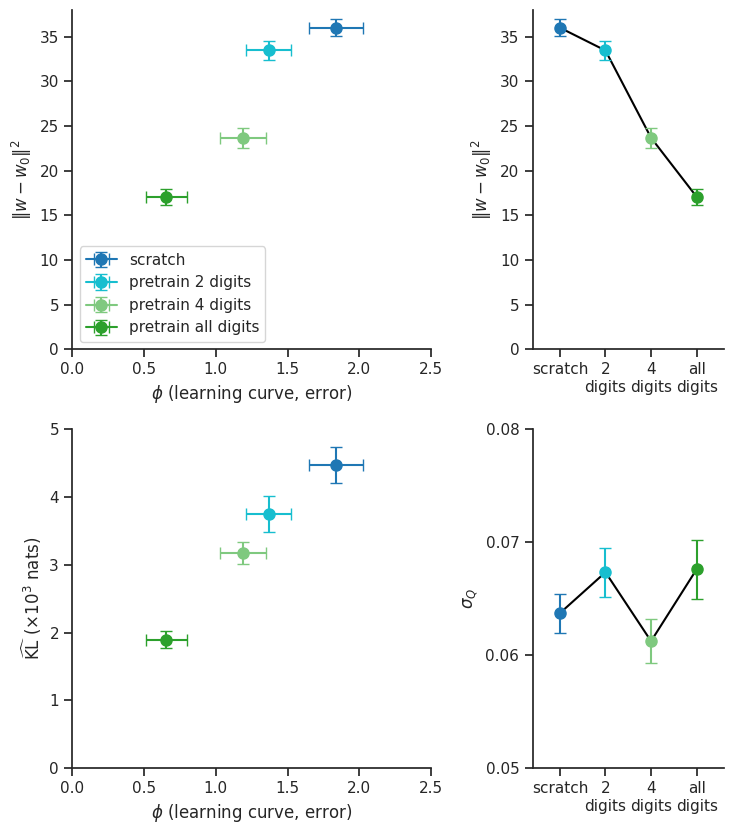

In [16]:
# the two measures against phi from the learning curve (early-stopped networks, test error; phi +- bootstrap
# sd), left; their ingredients per condition, right. Rows: distance from the init (measure 1), flatness KL
# (measure 2, distance in units of sigma_Q). Mean +- sem over repeats
from utils import plot_vs_phi, plot_agreement

fit, boot = es_results['error']['fits'], es_results['error']['boot']
sem = lambda v: v.std() / np.sqrt(len(v))
names = [k.replace('pretrain ', '').replace(' ', '\n') for k in conditions]
x = np.arange(len(names))

fig, axs = plt.subplots(2, 2, figsize=(7.5, 8.5), gridspec_kw={'width_ratios': [3, 1.6]})
rows = [('dist2', 1, r'$\|w - w_0\|^2$', 'dist2', r'$\|w - w_0\|^2$'),
        ('kl', 1e3, r'$\widehat{\mathrm{KL}}$ ($\times 10^3$ nats)', 'sigma', r'$\sigma_Q$')]
for (ax_phi, ax_cond), (q, scale, label, q_cond, label_cond) in zip(axs, rows):
    # measure vs phi
    plot_vs_phi(ax_phi, fit, boot, {cond: measures[cond][q] for cond in conditions}, colors, scale)
    ax_phi.set_xlim(0, 2.5)
    ax_phi.set_ylim(bottom=0)
    ax_phi.set_xlabel(r'$\phi$ (learning curve, error)')
    ax_phi.set_ylabel(label)

    # ingredient per condition
    est = [measures[cond][q_cond].mean() for cond in conditions]
    ax_cond.plot(x, est, color='black', zorder=1)
    for xi, cond in zip(x, conditions):
        ax_cond.errorbar(xi, est[xi], yerr=sem(measures[cond][q_cond]), color=colors[cond],
                         marker='o', markersize=8, capsize=4, zorder=2)
    ax_cond.set_ylim(bottom=0)
    ax_cond.set_ylabel(label_cond)
    ax_cond.set_xticks(x, names)
    ax_cond.set_xlim(-0.6, len(names) - 0.4)
axs[1, 0].set_ylim(0, 5)
axs[1, 1].set_ylim(0.05, 0.08)
axs[1, 1].set_yticks([0.05, 0.06, 0.07, 0.08])
axs[0, 0].legend()

plt.tight_layout()
plt.show()

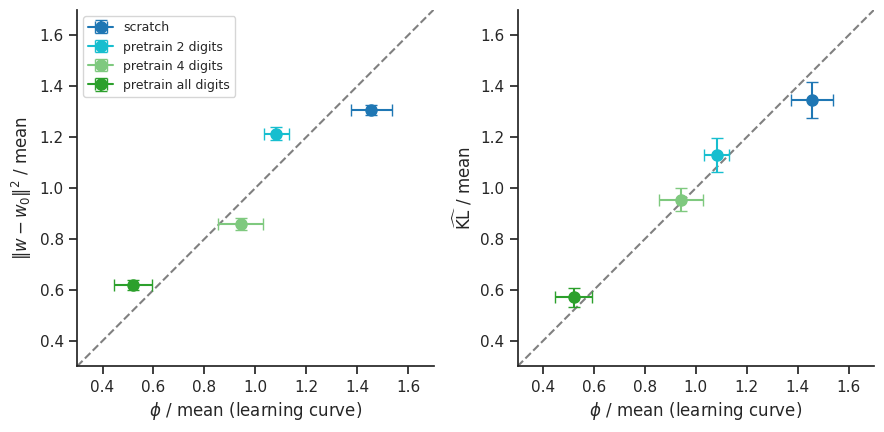

In [17]:
# agreement of the two measures with phi from the learning curve: each divided by its mean over the
# conditions, so a measure proportional to phi falls on the slope-1 line (the points average to (1, 1)).
# Error bars: bootstrap sd over repeats (the same indices for all conditions; phi from the fit bootstrap)
fig, axs = plt.subplots(1, 2, figsize=(9, 4.5))
for ax, (q, label) in zip(axs, (('dist2', r'$\|w - w_0\|^2$'), ('kl', r'$\widehat{\mathrm{KL}}$'))):
    plot_agreement(ax, fit, boot, {cond: measures[cond][q] for cond in conditions}, colors)
    ax.set_xlabel(r'$\phi$ / mean (learning curve)')
    ax.set_ylabel(label + ' / mean')
axs[0].legend(fontsize=9)
plt.tight_layout()
plt.show()

---
## Part 4: $\phi$ from the representation, without the weights
We want to estimate alignment from neural recordings. But in neural recordings we observe the representation, not the synaptic weights. 
So here we test if $\phi$ can be read from the representation of each condition's network **before** it learns the target task. 

Two methods, both on the conv2 layer with the same $m = 2^{10}$ training images as Part 3.

### 1. A linear decoder in place of the network weights
Train a linear readout of the target labels on the features $x = f_{w_0}(\text{image})$, and apply
the two measures of Part 3 to the decoder weights $W$, assume a prior centered at $0$.   
The decoder is ridge regression of the $\pm 1$-coded labels $Y$ on the z-scored features $X$
($m \times n$):

$$W = \arg\min_W \|XW - Y\|^2 + \lambda \|W\|^2 = X^\top (X X^\top + \lambda I)^{-1} Y,$$

If the task is already laid out along
the high-variance directions of the representation, a small $W$ suffices; if it lies in low-variance
directions, $W$ must be large. 

The measures like before: $\|W\|^2$, and the flatness-calibrated
$\widehat{\mathrm{KL}} = \frac{k}{2}\log\left(1 + \|W\|^2 / k\sigma_Q^2\right)$ as in Part 3.  

Use a set $\lambda$ for all conditions ($\lambda = 500$), selected with cross-validation.

**Choice of $\lambda$.** In the eigenbasis of the kernel $K = XX^\top$ (eigenvalues $\lambda_i$, label power
$a_i^2$ on each eigenvector), $\|W\|^2 = \sum_i a_i^2 \lambda_i / (\lambda_i + \lambda)^2$. For $\lambda \to 0$
(OLS: the minimum-norm interpolating decoder) this is $\sum_i a_i^2 / \lambda_i$, dominated by the weakest
directions of the representation (and the decoder overfits); for large $\lambda$ it is
$\sum_i \lambda_i a_i^2 / \lambda^2$, the (unnormalized) kernel alignment, which reverses the order. The
norm follows $\phi$ in the range where the decoder generalizes best ($\lambda \approx 500$-$1000$, the
lowest test error; the leave-one-out optimum is $\approx 560$ for every condition), so $\lambda$ is set there:
the measure is the norm of the best-generalizing decoder.

In [18]:
# ridge decoders of the target labels from the frozen conv2 features of each condition's init network, at
# m = m_kl (the same training images as the networks), for every repeat
from network_utils import evaluate, subset, frozen_features, zscore, ridge_probe, flatness_sigma, pac_bayes_kl

probe_layer = 'conv2'
lam_probe = 500.0  # ridge strength, the same for all conditions
X_pool, y_pool, X_test, y_test = target

probes = {}
for cond, res in nets.items():
    out = {q: np.zeros(n_repeat) for q in ('train_error', 'test_error', 'dist2', 'sigma')}
    for r in range(n_repeat):
        F_pool, F_test = (frozen_features(res['init'][r], X, probe_layer) for X in (X_pool, X_test))
        F_train, y_train = subset(F_pool, y_pool, m_kl, r)
        F_train, F_eval = zscore(F_train, F_test)
        probe, _ = ridge_probe(F_train, y_train, n_classes=3, lambdas=[lam_probe])
        out['train_error'][r] = evaluate(probe, F_train, y_train)[0]
        out['test_error'][r] = evaluate(probe, F_eval, y_test)[0]
        out['dist2'][r] = probe.weight.pow(2).sum().item()
        out['sigma'][r] = flatness_sigma(probe, F_train, y_train, hi=10.0)
    k = sum(p.numel() for p in probe.parameters())
    out['kl'] = pac_bayes_kl(out['dist2'], out['sigma'], k)
    probes[cond] = out

print(f'{probe_layer} features, m = {m_kl}, lambda = {lam_probe:g}, k = {k} decoder parameters; mean over repeats')
for cond, out in probes.items():
    print(f"{cond:20s} train / test error {out['train_error'].mean():.4f} / {out['test_error'].mean():.4f}  "
          f"d2 {out['dist2'].mean():.4f}  sigma_Q {out['sigma'].mean():.4f}  KL {out['kl'].mean():6.1f}")

conv2 features, m = 1024, lambda = 500, k = 9411 decoder parameters; mean over repeats
scratch              train / test error 0.0001 / 0.0200  d2 0.1989  sigma_Q 0.0221  KL  200.5
pretrain 2 digits    train / test error 0.0001 / 0.0193  d2 0.1773  sigma_Q 0.0223  KL  175.8
pretrain 4 digits    train / test error 0.0001 / 0.0161  d2 0.1606  sigma_Q 0.0229  KL  151.0
pretrain all digits  train / test error 0.0000 / 0.0157  d2 0.1516  sigma_Q 0.0228  KL  144.2


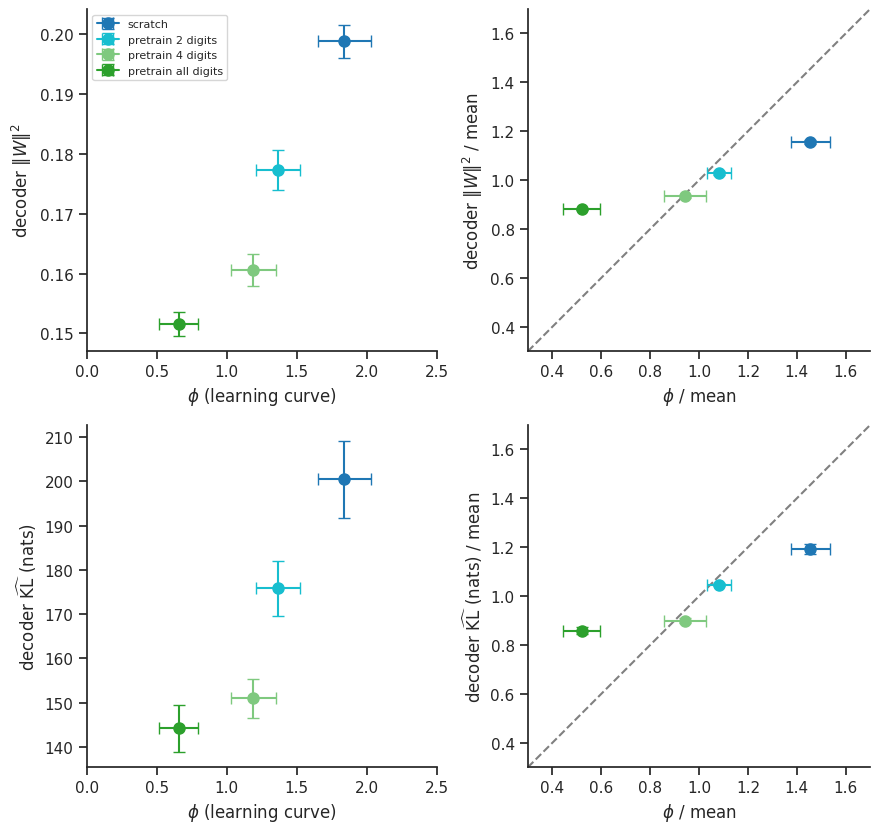

In [19]:
# decoder measures against phi from the learning curve (Part 3): raw (left), and each divided by its mean
# over the conditions (right; the slope-1 line = proportional to phi)
fig, axs = plt.subplots(2, 2, figsize=(9, 8.5))
for row, (q, label) in zip(axs, (('dist2', r'decoder $\|W\|^2$'), ('kl', r'decoder $\widehat{\mathrm{KL}}$ (nats)'))):
    values = {cond: probes[cond][q] for cond in conditions}
    plot_vs_phi(row[0], fit, boot, values, colors)
    row[0].set_xlim(0, 2.5)
    row[0].set_ylabel(label)
    plot_agreement(row[1], fit, boot, values, colors)
    row[1].set_ylabel(label + ' / mean')
for ax in axs[:, 0]:
    ax.set_xlabel(r'$\phi$ (learning curve)')
for ax in axs[:, 1]:
    ax.set_xlabel(r'$\phi$ / mean')
axs[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

### 2. Kernel-target alignment
Compare the similarity structure of the representation with that of the labels. With
the centered linear kernel between stimuli $K = X_c X_c^\top$ ($m \times m$, z-scored features) and the label
kernel $L = Y_c Y_c^\top$ (one-hot $Y$),

$$A = \frac{\langle K, L \rangle_F}{\|K\|_F \, \|L\|_F} \in [0, 1].$$

In the eigenbasis of the representation (principal components $u_i$ with variances $\lambda_i$; label power
$a_i^2 = \|u_i^\top Y_c\|^2$ on each),

$$A = \frac{\sum_i \lambda_i a_i^2}{\sqrt{\sum_i \lambda_i^2}\, \|L\|_F}:$$

high when the labels lie along the high-variance directions of the representation.  

As the complexity we use the misalignment $-\log A$: $0$ for a representation whose similarity
structure is that of the labels ($A = 1$, nothing to learn), growing without bound as the alignment vanishes.

scratch              alignment A 0.2642  -log A 1.3325


pretrain 2 digits    alignment A 0.2835  -log A 1.2617


pretrain 4 digits    alignment A 0.3065  -log A 1.1838


pretrain all digits  alignment A 0.3232  -log A 1.1303


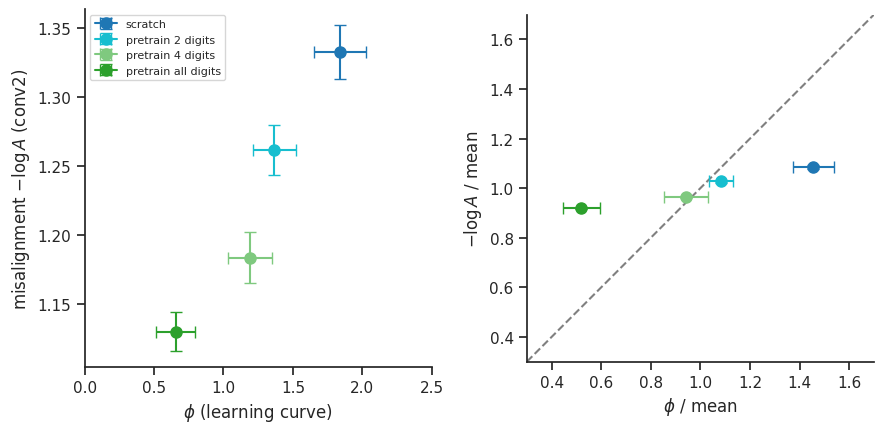

In [20]:
# kernel-target alignment of the frozen conv2 features on the m = m_kl training images of each repeat;
# misalignment -log A, raw (left) and divided by its mean over the conditions (right)
from utils import kernel_alignment

alignment = {}
for cond, res in nets.items():
    alignment[cond] = np.zeros(n_repeat)
    for r in range(n_repeat):
        F_train, y_train = subset(frozen_features(res['init'][r], X_pool, probe_layer), y_pool, m_kl, r)
        alignment[cond][r] = kernel_alignment(zscore(F_train)[0].cpu().numpy(), y_train.cpu().numpy())
    print(f'{cond:20s} alignment A {alignment[cond].mean():.4f}  -log A {-np.log(alignment[cond]).mean():.4f}')

misalignment = {cond: -np.log(alignment[cond]) for cond in conditions}

fig, axs = plt.subplots(1, 2, figsize=(9, 4.5))
plot_vs_phi(axs[0], fit, boot, misalignment, colors)
axs[0].set_xlim(0, 2.5)
axs[0].set_xlabel(r'$\phi$ (learning curve)')
axs[0].set_ylabel(f'misalignment $-\\log A$ ({probe_layer})')
axs[0].legend(fontsize=8)
plot_agreement(axs[1], fit, boot, misalignment, colors)
axs[1].set_xlabel(r'$\phi$ / mean')
axs[1].set_ylabel(r'$-\log A$ / mean')
plt.tight_layout()
plt.show()